In [10]:
import urllib.request
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/481/emg+data+for+gestures.zip", "emg.zip")
zipfile.ZipFile("emg.zip").extractall()

In [11]:
import pandas as pd
df = pd.read_csv("EMG_data_for_gestures-master/01/1_raw_data_13-12_22.03.16.txt", sep="\t")
print(len(df))
print(list(df.columns))
print(df["class"].value_counts().sort_index())

63196
['time', 'channel1', 'channel2', 'channel3', 'channel4', 'channel5', 'channel6', 'channel7', 'channel8', 'class']
class
0    41272
1     3780
2     3525
3     3816
4     3441
5     3615
6     3747
Name: count, dtype: int64


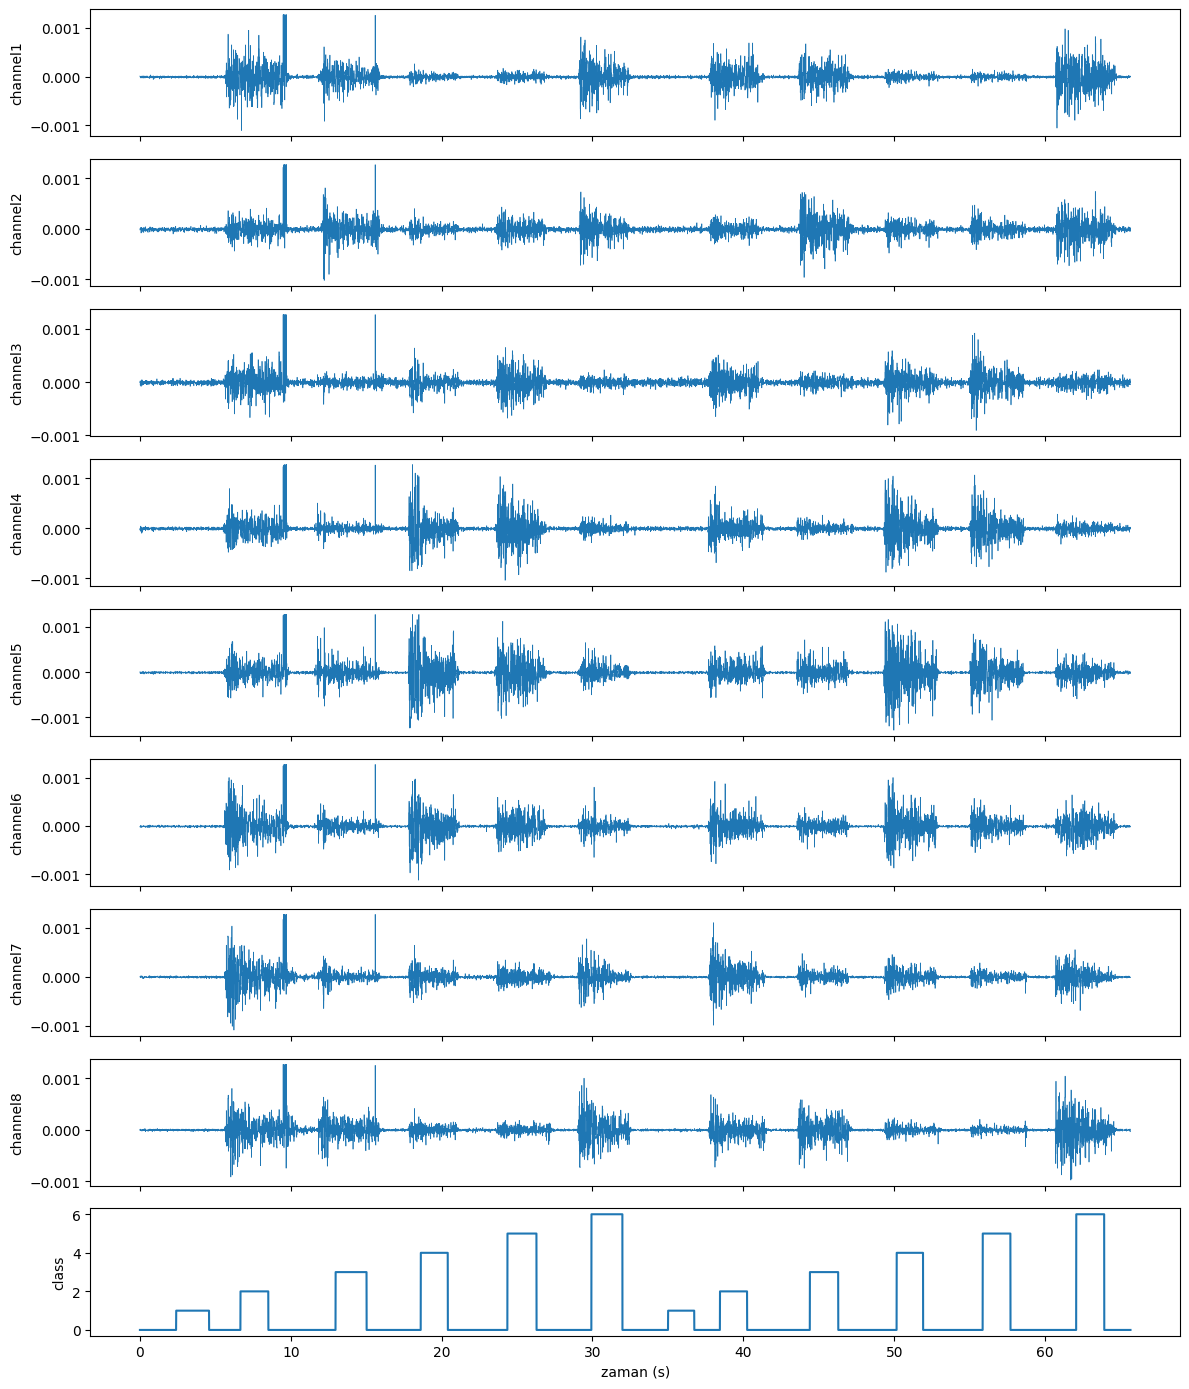

In [12]:
import matplotlib.pyplot as plt

t = df["time"] / 1000

fig, ax = plt.subplots(9, 1, sharex=True, figsize=(12, 14))

for i in range(8):
    kanal_adi = f"channel{i+1}"
    ax[i].plot(t, df[kanal_adi], linewidth=0.5)
    ax[i].set_ylabel(kanal_adi)

ax[8].plot(t, df["class"])
ax[8].set_ylabel("class")
ax[8].set_xlabel("zaman (s)")

plt.tight_layout()
plt.savefig("sekil1.png", dpi=100)
plt.show()

Grafikleri incelediğimde, class etiketinin yükseldiği anlar ile üstteki EMG kanallarındaki sinyal patlamalarının genel olarak aynı anda başladığını gözlemledim

In [13]:
import numpy as np

x = df["channel1"].abs()
d = x[df["class"] == 1]
esik = d.mean() + 3 * d.std()

tahmin = (x > esik).to_numpy()
gercek = df["class"].between(2, 7).to_numpy()
m = (df["class"] != 0).to_numpy()

def f1(tah, ger):
    TP = np.sum(tah & ger)
    FP = np.sum(tah & ~ger)
    FN = np.sum(~tah & ger)
    return 2 * TP / (2 * TP + FP + FN)

n = m.sum()

print(f"Baseline F1 = {round(f1(tahmin[m], gercek[m]), 3):.3f}")
print(f"Hep aktif F1 = {round(f1(np.ones(n, dtype=bool), gercek[m]), 3):.3f}")
print(f"Sağlama = {round(f1(gercek[m], gercek[m]), 3):.3f}")

Baseline F1 = 0.781
Hep aktif F1 = 0.906
Sağlama = 1.000


İlk yöntem F1 = 1.000
TP = 18144
FP = 0
FN = 0


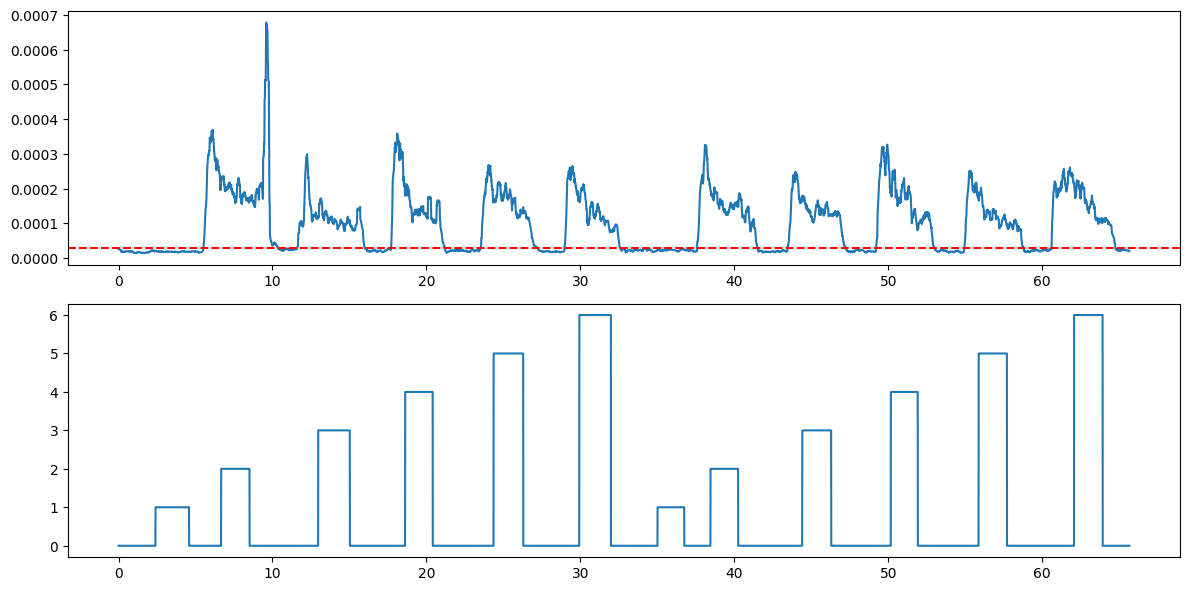

In [14]:
import numpy as np
import matplotlib.pyplot as plt

kanallar = [f"channel{i}" for i in range(1, 9)]
zarf = np.sqrt((df[kanallar] ** 2).rolling(200, center=True, min_periods=1).mean()).mean(axis=1)

d2 = zarf[df["class"] == 1]
esik2 = d2.mean() + 3 * d2.std()
tahmin2 = (zarf > esik2).to_numpy()

print(f"İlk yöntem F1 = {round(f1(tahmin2[m], gercek[m]), 3):.3f}")

TP2 = np.sum(tahmin2[m] & gercek[m])
FP2 = np.sum(tahmin2[m] & ~gercek[m])
FN2 = np.sum(~tahmin2[m] & gercek[m])

print(f"TP = {int(TP2)}")
print(f"FP = {int(FP2)}")
print(f"FN = {int(FN2)}")

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
x = df["time"] / 1000

ax[0].plot(x, zarf)
ax[0].axhline(y=esik2, color='red', linestyle='--')
ax[1].plot(x, df["class"])

plt.tight_layout()
plt.savefig("sekil2.png", dpi=100)
plt.show()

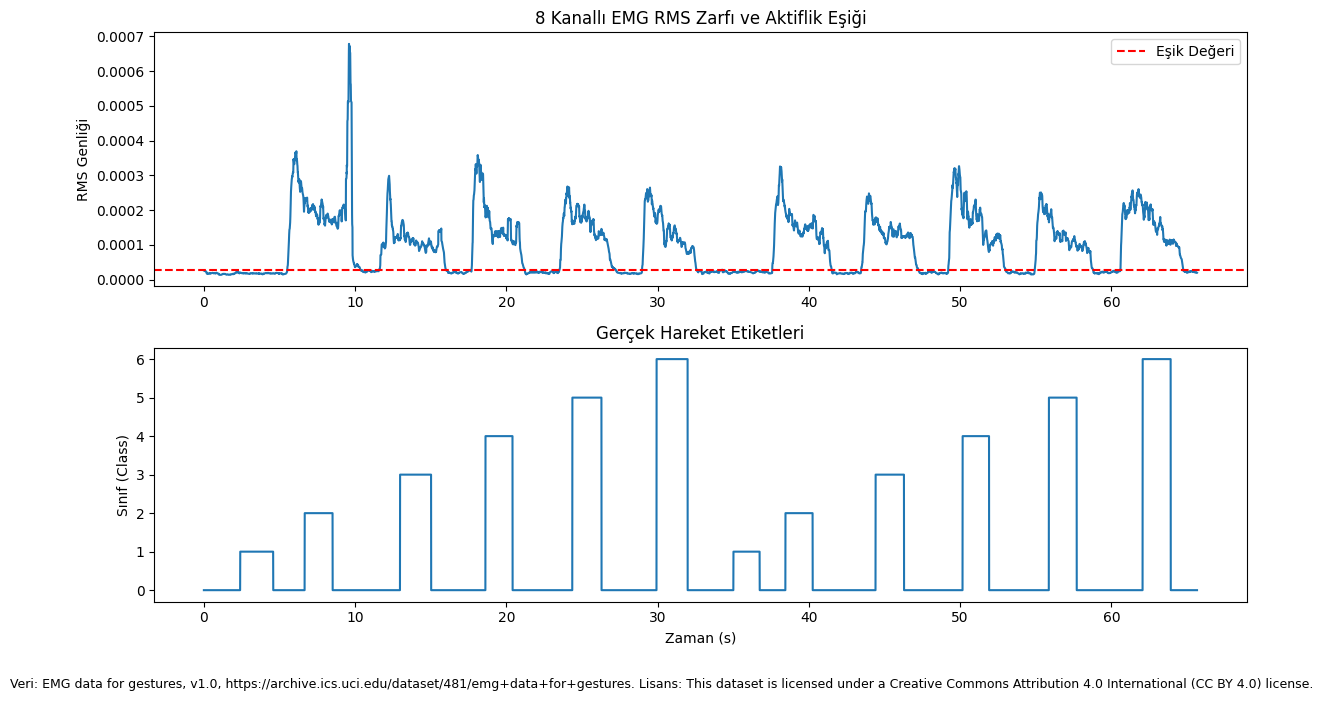

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
x_zaman = df["time"] / 1000

# Üst grafik: RMS Zarfı
ax[0].plot(x_zaman, zarf)
ax[0].axhline(y=esik2, color='red', linestyle='--', label='Eşik Değeri')
ax[0].set_title("8 Kanallı EMG RMS Zarfı ve Aktiflik Eşiği")
ax[0].set_ylabel("RMS Genliği")
ax[0].legend()

# Alt grafik: Etiketler
ax[1].plot(x_zaman, df["class"])
ax[1].set_title("Gerçek Hareket Etiketleri")
ax[1].set_ylabel("Sınıf (Class)")
ax[1].set_xlabel("Zaman (s)")

# Alt bilgiye yer açmak için grafikleri biraz yukarı sıkıştırıyoruz
plt.tight_layout(rect=[0, 0.05, 1, 1])

# Alt bilgi metni (LİSANSI_BURAYA_YAZIN kısmını siz dolduracaksınız)
alt_bilgi = "Veri: EMG data for gestures, v1.0, https://archive.ics.uci.edu/dataset/481/emg+data+for+gestures. Lisans: This dataset is licensed under a Creative Commons Attribution 4.0 International (CC BY 4.0) license."
plt.figtext(0.5, 0.01, alt_bilgi, ha="center", fontsize=9)

plt.savefig("sekil_github.png", dpi=100)
plt.show()

In [16]:
import os
import glob
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

dosyalar = sorted(glob.glob("EMG_data_for_gestures-master/*/*_raw_data_*.txt"))
kanallar = [f"channel{i}" for i in range(1, 9)]

veri_listesi = []

for dosya in dosyalar:
    kisi_no = os.path.basename(os.path.dirname(dosya))
    df_dosya = pd.read_csv(dosya, sep="\t")
    df_dosya.columns = [c.strip() for c in df_dosya.columns]

    zarf_dosya = np.sqrt((df_dosya[kanallar] ** 2).rolling(200, center=True, min_periods=1).mean()).mean(axis=1)

    temp_df = pd.DataFrame({
        "kisi": kisi_no,
        "channel1": df_dosya["channel1"].abs(),
        "zarf": zarf_dosya,
        "class": df_dosya["class"]
    })
    veri_listesi.append(temp_df)

df_tum = pd.concat(veri_listesi, ignore_index=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df_tum, groups=df_tum["kisi"]))

train_df = df_tum.iloc[train_idx]
test_df = df_tum.iloc[test_idx]

train_kisiler = sorted(train_df["kisi"].unique())
test_kisiler = sorted(test_df["kisi"].unique())

print(f"Toplam dosya sayısı: {len(dosyalar)}")
print(f"Eğitimdeki kişi sayısı: {len(train_kisiler)}")
print(f"Testteki kişi sayısı: {len(test_kisiler)}")
print(f"Ortak kişi var mı (Sızıntı kontrolü): {bool(set(train_kisiler).intersection(set(test_kisiler)))}")

d_train = train_df[train_df["class"] == 1]["zarf"]
esik = d_train.mean() + 3 * d_train.std()

d_base_train = train_df[train_df["class"] == 1]["channel1"]
esik_base = d_base_train.mean() + 3 * d_base_train.std()

tahmin_test = (test_df["zarf"] > esik).to_numpy()
tahmin_base_test = (test_df["channel1"] > esik_base).to_numpy()

gercek_test = test_df["class"].between(2, 7).to_numpy()
m_test = (test_df["class"] != 0).to_numpy()

def f1(tah, ger):
    TP = np.sum(tah & ger)
    FP = np.sum(tah & ~ger)
    FN = np.sum(~tah & ger)
    return 2 * TP / (2 * TP + FP + FN)

test_f1 = f1(tahmin_test[m_test], gercek_test[m_test])
baseline_test_f1 = f1(tahmin_base_test[m_test], gercek_test[m_test])

TP = np.sum(tahmin_test[m_test] & gercek_test[m_test])
FP = np.sum(tahmin_test[m_test] & ~gercek_test[m_test])
FN = np.sum(~tahmin_test[m_test] & gercek_test[m_test])

print(f"Test Baseline F1 (Kanal 1) = {round(baseline_test_f1, 3):.3f}")
print(f"Test Yöntem F1 (8 Kanal RMS) = {round(test_f1, 3):.3f}")
print(f"TP = {int(TP)}")
print(f"FP = {int(FP)}")
print(f"FN = {int(FN)}")

Toplam dosya sayısı: 72
Eğitimdeki kişi sayısı: 28
Testteki kişi sayısı: 8
Ortak kişi var mı (Sızıntı kontrolü): False
Test Baseline F1 (Kanal 1) = 0.705
Test Yöntem F1 (8 Kanal RMS) = 0.980
TP = 276838
FP = 199
FN = 10880


In [18]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupKFold

# Verinin 'df' adlı DataFrame'de yüklü olduğu varsayılmıştır.
# n_splits=5 ile kişileri 5 farklı gruba bölüyoruz.
gkf = GroupKFold(n_splits=5)

baseline_f1_list = []
hep_aktif_f1_list = []
rms_f1_list = []

fold = 1
for train_idx, test_idx in gkf.split(df, groups=df['Kisi_No']):
    train_df = df.iloc[train_idx]
    test_df = df.iloc[test_idx]

    test_kisiler = test_df['Kisi_No'].unique()
    print(f"--- Bölme {fold} ---")
    print(f"Test Kişileri (Sızıntısız): {test_kisiler}")

    # Eşikleri YALNIZCA eğitim (train) kişilerinden hesapla
    train_class1 = train_df[train_df['Class'] == 1]

    # 1. Baseline Eşiği (Kanal 1)
    esik_baseline = train_class1['Kanal1'].abs().mean() + 3 * train_class1['Kanal1'].abs().std()

    # 2. RMS Eşiği (8 Kanal)
    train_rms = np.sqrt((train_df.loc[:, 'Kanal1':'Kanal8']**2).mean(axis=1))
    esik_rms = train_rms[train_df['Class'] == 1].mean() + 3 * train_rms[train_df['Class'] == 1].std()

    # TEST aşaması (Sadece m_test ile Class 0 dışarıda bırakılır)
    m_test = test_df['Class'] != 0
    y_true = (test_df.loc[m_test, 'Class'] > 1).astype(int)

    # Baseline Tahmini
    y_pred_base = (test_df.loc[m_test, 'Kanal1'].abs() > esik_baseline).astype(int)
    f1_base = f1_score(y_true, y_pred_base)
    baseline_f1_list.append(f1_base)

    # Hep Aktif Tahmini
    y_pred_hep = np.ones_like(y_true)
    f1_hep = f1_score(y_true, y_pred_hep)
    hep_aktif_f1_list.append(f1_hep)

    # RMS Tahmini
    test_rms = np.sqrt((test_df.loc[m_test, 'Kanal1':'Kanal8']**2).mean(axis=1))
    y_pred_rms = (test_rms > esik_rms).astype(int)
    f1_rms = f1_score(y_true, y_pred_rms)
    rms_f1_list.append(f1_rms)

    print(f"Baseline F1: {f1_base:.3f} | Hep Aktif F1: {f1_hep:.3f} | 8 Kanal RMS F1: {f1_rms:.3f}\n")
    fold += 1

print("=== 5 BÖLME ORTALAMA ± SAPMA (TEST KİŞİLERİNDE) ===")
print(f"Baseline F1    : {np.mean(baseline_f1_list):.3f} ± {np.std(baseline_f1_list):.3f}")
print(f"Hep Aktif F1   : {np.mean(hep_aktif_f1_list):.3f} ± {np.std(hep_aktif_f1_list):.3f}")
print(f"8 Kanal RMS F1 : {np.mean(rms_f1_list):.3f} ± {np.std(rms_f1_list):.3f}")

KeyError: 'Kisi_No'

In [20]:
# 1. Aşama: Aynı test kişilerinde 'hep aktif' F1 skoru (Class 0 dışarıda)
tahmin_hep_aktif = np.ones_like(gercek_test, dtype=bool)
hep_aktif_f1 = f1(tahmin_hep_aktif[m_test], gercek_test[m_test])

print(f"Test Hep Aktif F1 = {hep_aktif_f1:.3f}")

Test Hep Aktif F1 = 0.910


In [21]:
from sklearn.model_selection import GroupKFold

# 5 farklı kişi bölmesi (kat) oluşturuyoruz
gkf = GroupKFold(n_splits=5)

baseline_f1_list = []
hep_aktif_f1_list = []
rms_f1_list = []

fold = 1
for train_idx, test_idx in gkf.split(df_tum, groups=df_tum["kisi"]):
    train_df = df_tum.iloc[train_idx]
    test_df = df_tum.iloc[test_idx]

    # Test kişilerinin listesi
    test_kisiler = sorted(test_df["kisi"].unique())
    print(f"--- Bölme {fold} ---")
    print(f"Test Kişileri: {test_kisiler}")

    # Eşikleri YALNIZCA eğitim (train) kişilerinden hesapla
    d_train = train_df[train_df["class"] == 1]["zarf"]
    esik = d_train.mean() + 3 * d_train.std()

    d_base_train = train_df[train_df["class"] == 1]["channel1"]
    esik_base = d_base_train.mean() + 3 * d_base_train.std()

    # Test verisi için tahminler
    tahmin_test = (test_df["zarf"] > esik).to_numpy()
    tahmin_base_test = (test_df["channel1"] > esik_base).to_numpy()
    tahmin_hep_aktif = np.ones(len(test_df), dtype=bool)

    # Gerçek değerler ve maske (Class 0 dışarıda)
    gercek_test = test_df["class"].between(2, 7).to_numpy()
    m_test = (test_df["class"] != 0).to_numpy()

    # F1 Skorları (8. hücredeki kendi f1 fonksiyonunu kullanarak)
    f1_base = f1(tahmin_base_test[m_test], gercek_test[m_test])
    f1_hep = f1(tahmin_hep_aktif[m_test], gercek_test[m_test])
    f1_rms = f1(tahmin_test[m_test], gercek_test[m_test])

    baseline_f1_list.append(f1_base)
    hep_aktif_f1_list.append(f1_hep)
    rms_f1_list.append(f1_rms)

    print(f"Baseline F1: {f1_base:.3f} | Hep Aktif F1: {f1_hep:.3f} | 8 Kanal RMS F1: {f1_rms:.3f}\n")
    fold += 1

# En son Ortalama ± Sapma değerleri
print("=== 5 BÖLME ORTALAMA ± SAPMA (TEST KİŞİLERİNDE) ===")
print(f"Kanal 1 Baseline : {np.mean(baseline_f1_list):.3f} ± {np.std(baseline_f1_list):.3f}")
print(f"Hep Aktif (Dummy): {np.mean(hep_aktif_f1_list):.3f} ± {np.std(hep_aktif_f1_list):.3f}")
print(f"8 Kanal RMS      : {np.mean(rms_f1_list):.3f} ± {np.std(rms_f1_list):.3f}")

--- Bölme 1 ---
Test Kişileri: ['13', '14', '20', '22', '23', '27', '29']
Baseline F1: 0.711 | Hep Aktif F1: 0.909 | 8 Kanal RMS F1: 0.980

--- Bölme 2 ---
Test Kişileri: ['01', '12', '15', '19', '24', '28', '30', '31']
Baseline F1: 0.637 | Hep Aktif F1: 0.912 | 8 Kanal RMS F1: 0.984

--- Bölme 3 ---
Test Kişileri: ['03', '05', '06', '11', '18', '25', '32']
Baseline F1: 0.738 | Hep Aktif F1: 0.915 | 8 Kanal RMS F1: 0.991

--- Bölme 4 ---
Test Kişileri: ['02', '04', '10', '16', '21', '34', '35']
Baseline F1: 0.704 | Hep Aktif F1: 0.911 | 8 Kanal RMS F1: 0.999

--- Bölme 5 ---
Test Kişileri: ['07', '08', '09', '17', '26', '33', '36']
Baseline F1: 0.750 | Hep Aktif F1: 0.902 | 8 Kanal RMS F1: 0.983

=== 5 BÖLME ORTALAMA ± SAPMA (TEST KİŞİLERİNDE) ===
Kanal 1 Baseline : 0.708 ± 0.039
Hep Aktif (Dummy): 0.910 ± 0.004
8 Kanal RMS      : 0.987 ± 0.007


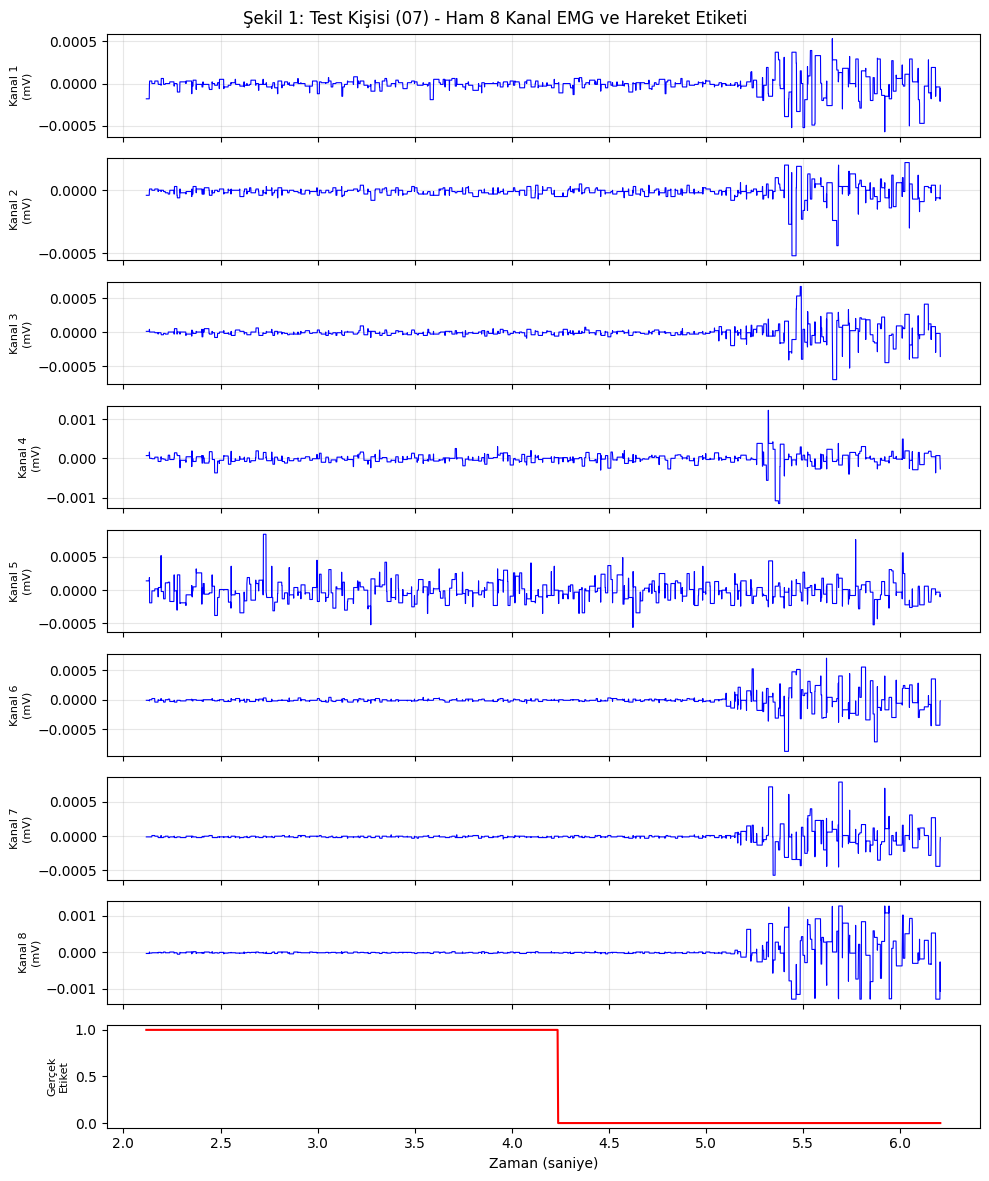

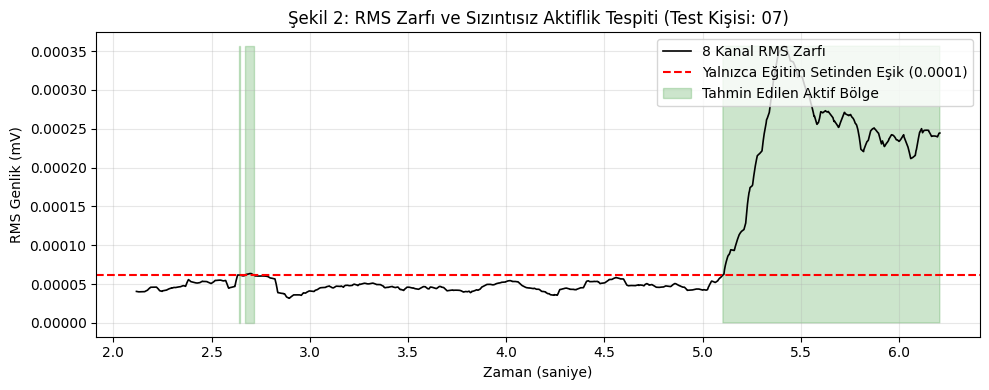

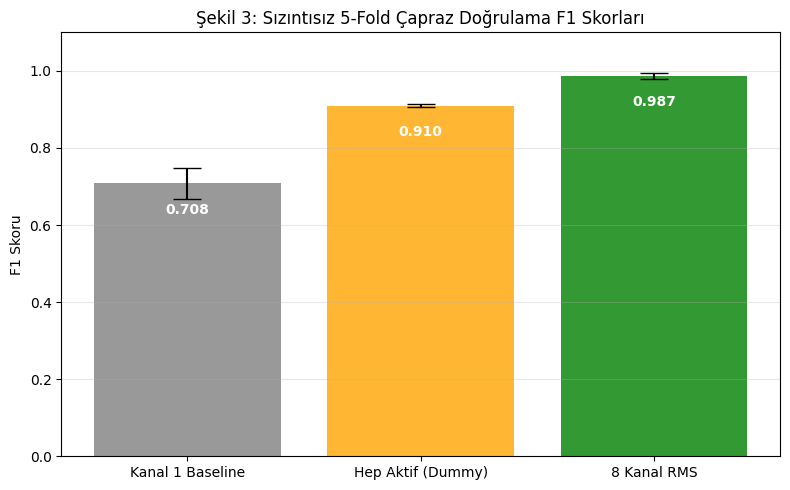

In [22]:
import matplotlib.pyplot as plt
import os

# 1. 5. Bölmedeki test grubundan bir kişiyi (örneğin ilk kişiyi) seçelim
test_kisi = test_kisiler[0]
secilen_dosya = [d for d in dosyalar if test_kisi in os.path.basename(os.path.dirname(d))][0]

# Sadece grafik için bu dosyayı ham haliyle okuyalım (Kanal 2-8'i görmek için)
df_grafik = pd.read_csv(secilen_dosya, sep="\t")
df_grafik.columns = [c.strip() for c in df_grafik.columns]

# Birkaç saniyelik kesit alalım (örneğin 2000. ile 6000. satırlar arası)
bas, bit = 2000, 6000
df_kesit = df_grafik.iloc[bas:bit].copy()
zaman = df_kesit['time'] / 1000.0  # ms'den saniyeye çevrim

# ŞEKİL 1: Ham 8 Kanal ve Gerçek Etiket
fig1, axs1 = plt.subplots(9, 1, figsize=(10, 12), sharex=True)
kanallar_tam = [f'channel{i}' for i in range(1, 9)]
for i, kanal in enumerate(kanallar_tam):
    axs1[i].plot(zaman, df_kesit[kanal], color='blue', linewidth=0.8)
    axs1[i].set_ylabel(f'Kanal {i+1}\n(mV)', fontsize=8)
    axs1[i].grid(True, alpha=0.3)

axs1[8].plot(zaman, df_kesit['class'], color='red', linewidth=1.5)
axs1[8].set_ylabel('Gerçek\nEtiket', fontsize=8)
axs1[8].set_xlabel('Zaman (saniye)', fontsize=10)
fig1.suptitle(f"Şekil 1: Test Kişisi ({test_kisi}) - Ham 8 Kanal EMG ve Hareket Etiketi", fontsize=12)
plt.tight_layout()
plt.savefig("sekil1.png", dpi=300)

# ŞEKİL 2: RMS Zarfı, Eğitim Eşiği ve Tahmin
rms_kesit = np.sqrt((df_kesit[kanallar_tam] ** 2).rolling(200, center=True, min_periods=1).mean()).mean(axis=1)

fig2, ax2 = plt.subplots(figsize=(10, 4))
ax2.plot(zaman, rms_kesit, label='8 Kanal RMS Zarfı', color='black', linewidth=1.2)
ax2.axhline(y=esik, color='red', linestyle='--', label=f'Yalnızca Eğitim Setinden Eşik ({esik:.4f})')

tahmin_aktif = rms_kesit > esik
ax2.fill_between(zaman, 0, rms_kesit.max(), where=tahmin_aktif, color='green', alpha=0.2, label='Tahmin Edilen Aktif Bölge')

ax2.set_xlabel('Zaman (saniye)', fontsize=10)
ax2.set_ylabel('RMS Genlik (mV)', fontsize=10)
ax2.set_title(f"Şekil 2: RMS Zarfı ve Sızıntısız Aktiflik Tespiti (Test Kişisi: {test_kisi})", fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("sekil2.png", dpi=300)

# ŞEKİL 3: F1 Çubuk Grafiği (5 Bölmeli Hata Çubuklu)
fig3, ax3 = plt.subplots(figsize=(8, 5))
yontemler = ['Kanal 1 Baseline', 'Hep Aktif (Dummy)', '8 Kanal RMS']
ortalamalar = [np.mean(baseline_f1_list), np.mean(hep_aktif_f1_list), np.mean(rms_f1_list)]
sapmalar = [np.std(baseline_f1_list), np.std(hep_aktif_f1_list), np.std(rms_f1_list)]

bars = ax3.bar(yontemler, ortalamalar, yerr=sapmalar, capsize=10, color=['gray', 'orange', 'green'], alpha=0.8)
ax3.set_ylim(0, 1.1)
ax3.set_ylabel('F1 Skoru', fontsize=10)
ax3.set_title('Şekil 3: Sızıntısız 5-Fold Çapraz Doğrulama F1 Skorları', fontsize=12)

for bar in bars:
    yval = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, yval - 0.05, f"{yval:.3f}", ha='center', va='top', color='white', fontweight='bold')

ax3.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("sekil3.png", dpi=300)
plt.show()